# Step 7 — How often does an agent hold fire at 15 players?

Step 1 trained three seeds at 15 players. Two essentially never abstained; one held fire in
0.2976 of its decisions, almost all of them early in the game. Three seeds can show that this
happens but not how often. This step trains ten, so the share of seeds that hold fire becomes
a rate with an error bar.

Nothing else changes: `terminal` reward, `ranked` seating, step 1's budget. Seeds 0 to 2 are
step 1's own seeds, so they should reproduce its numbers exactly.

In [1]:
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from gruel_env import GruelEnv, N_ACTIONS, MISS, SHOOT_LEFT, SHOOT_RIGHT

torch.set_num_threads(1)
print("torch", torch.__version__)

torch 2.2.2


## Settings

In [2]:
N = 15
REWARD = "terminal"
SEATING = "ranked"
SEEDS = list(range(10))

OBSERVATION_SIZE = 4
HIDDEN_SIZE = 64

UPDATES = 2000
EPISODES_PER_UPDATE = 96
EVALUATION_EPISODES = 10000
REFERENCE_EPISODES = 10000

LEARNING_RATE = 0.003
CLIP = 0.2
EPOCHS = 4
MINIBATCH_SIZE = 256
VALUE_COEFFICIENT = 0.5
ENTROPY_COEFFICIENT = 0.01

# The same threshold as deliverable 03's steps 7 and 8: two targeting profiles are the same
# policy if their mean distance, rank by rank, is at most this.
MATCH_THRESHOLD = 0.10

# A run "holds fire" if more than this share of its decisions are deliberate misses, the same
# threshold step 1 used to decide which runs to break down.
HOLDS_FIRE_THRESHOLD = 0.01

print("N:", N, " reward:", REWARD, " seating:", SEATING)
print("budget per run:", UPDATES, "updates x", EPISODES_PER_UPDATE, "episodes =",
      UPDATES * EPISODES_PER_UPDATE, "training episodes")
print("seeds:", SEEDS)

N: 15  reward: terminal  seating: ranked
budget per run: 2000 updates x 96 episodes = 192000 training episodes
seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## The agent and the measurement machinery, copied forward

Every definition below is step 1's, copied forward. Rule 1 says a step copies the
previous step forward rather than importing it, so this folder carries its own copy and
can be handed over on its own.

One change: `play_episodes` also records how long each episode lasted and what every
player had banked by the end, because the shaped reward pays throughout the episode and
both numbers are needed to check it.

`collect_batch` reads each player's return from the environment rather than assuming
`1.0 for the winner, 0.0 for everyone else`. Under `terminal` the two are identical, so
nothing here depends on it; it matters the moment a shaped reward is used.

In [3]:
class SharedActorCritic(nn.Module):
    def __init__(self, n_players):
        super().__init__()
        self.n_players = n_players
        self.actor_first = nn.Linear(OBSERVATION_SIZE, HIDDEN_SIZE)
        self.actor_second = nn.Linear(HIDDEN_SIZE, N_ACTIONS)
        critic_input_size = 2 * n_players + n_players
        self.critic_first = nn.Linear(critic_input_size, HIDDEN_SIZE)
        self.critic_second = nn.Linear(HIDDEN_SIZE, 1)
        self.activation = nn.Tanh()

    def action_logits(self, observation):
        hidden = self.activation(self.actor_first(observation))
        return self.actor_second(hidden)

    def value(self, state, agent_one_hot):
        combined = torch.cat([state, agent_one_hot], dim=-1)
        hidden = self.activation(self.critic_first(combined))
        return self.critic_second(hidden).squeeze(-1)


def global_state(game):
    numbers = []
    for position in range(game.n):
        numbers.append(game.accuracies[position])
        if position in game.order:
            numbers.append(1.0)
        else:
            numbers.append(0.0)
    return np.array(numbers, dtype=np.float32)


def one_hot(position, n_players):
    vector = np.zeros(n_players, dtype=np.float32)
    vector[position] = 1.0
    return vector


def collect_batch(model, game, episodes):
    observations = {p: [] for p in range(game.n)}
    actions = {p: [] for p in range(game.n)}
    old_log_probabilities = {p: [] for p in range(game.n)}
    values = {p: [] for p in range(game.n)}
    returns = {p: [] for p in range(game.n)}
    states = {p: [] for p in range(game.n)}
    agent_flags = {p: [] for p in range(game.n)}

    for _ in range(episodes):
        game.reset()
        episode_observations = {p: [] for p in range(game.n)}
        episode_actions = {p: [] for p in range(game.n)}
        episode_log_probabilities = {p: [] for p in range(game.n)}
        episode_values = {p: [] for p in range(game.n)}
        episode_states = {p: [] for p in range(game.n)}
        episode_flags = {p: [] for p in range(game.n)}
        # What each player had already banked when it made each decision. Needed because
        # the return for a decision is whatever arrives AFTER it, and under `shaped`
        # rewards arrive throughout the episode rather than only at the end.
        episode_banked_before = {p: [] for p in range(game.n)}

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()

            # A finished agent is handed to us one last time, so PettingZoo can retire
            # it. Stepping with None is how we say 'nothing to do here'.
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            banked_so_far = float(game.episode_returns[acting_agent])
            observation_tensor = torch.from_numpy(observation)
            state_array = global_state(game)
            agent_array = one_hot(actor, game.n)

            with torch.no_grad():
                logits = model.action_logits(observation_tensor)
                value = model.value(torch.from_numpy(state_array),
                                    torch.from_numpy(agent_array))

            distribution = torch.distributions.Categorical(logits=logits)
            action = distribution.sample()

            episode_observations[actor].append(observation)
            episode_actions[actor].append(int(action))
            episode_log_probabilities[actor].append(float(distribution.log_prob(action)))
            episode_values[actor].append(float(value))
            episode_states[actor].append(state_array)
            episode_flags[actor].append(agent_array)
            episode_banked_before[actor].append(banked_so_far)

            game.step(int(action))

        for position in range(game.n):
            # The return for a decision is the reward-to-go: everything this player ended
            # the episode with, minus what it had already banked when it decided. With a
            # discount of 1 that is exactly the undiscounted sum of what came after.
            #
            # Reading it from the environment is the whole point of this step. Assuming
            # `1.0 for the winner, 0.0 for everyone else` is correct under `terminal` and
            # silently WRONG under `shaped`, where it would discard every kill bonus,
            # every elimination penalty and every survival tick -- and both arms would then
            # train on identical numbers and look identical for a reason that is a bug.
            name = game.agent_of_position[position]
            final_total = float(game.episode_returns[name])
            for index in range(len(episode_actions[position])):
                own_return = final_total - episode_banked_before[position][index]
                observations[position].append(episode_observations[position][index])
                actions[position].append(episode_actions[position][index])
                old_log_probabilities[position].append(
                    episode_log_probabilities[position][index])
                values[position].append(episode_values[position][index])
                states[position].append(episode_states[position][index])
                agent_flags[position].append(episode_flags[position][index])
                returns[position].append(own_return)

    flat_observations = []
    flat_actions = []
    flat_old_log_probabilities = []
    flat_values = []
    flat_returns = []
    flat_states = []
    flat_flags = []
    for position in range(game.n):
        flat_observations.extend(observations[position])
        flat_actions.extend(actions[position])
        flat_old_log_probabilities.extend(old_log_probabilities[position])
        flat_values.extend(values[position])
        flat_returns.extend(returns[position])
        flat_states.extend(states[position])
        flat_flags.extend(agent_flags[position])

    batch = {
        "observations": torch.tensor(np.array(flat_observations), dtype=torch.float32),
        "actions": torch.tensor(flat_actions, dtype=torch.long),
        "old_log_probabilities": torch.tensor(flat_old_log_probabilities,
                                              dtype=torch.float32),
        "values": torch.tensor(flat_values, dtype=torch.float32),
        "returns": torch.tensor(flat_returns, dtype=torch.float32),
        "states": torch.tensor(np.array(flat_states), dtype=torch.float32),
        "agent_flags": torch.tensor(np.array(flat_flags), dtype=torch.float32),
    }
    return batch


def ppo_update(model, optimiser, batch, update_rng):
    advantages = batch["returns"] - batch["values"]
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    count = len(batch["actions"])
    order = np.arange(count)

    for epoch in range(EPOCHS):
        update_rng.shuffle(order)
        for start in range(0, count, MINIBATCH_SIZE):
            chunk = order[start:start + MINIBATCH_SIZE]
            index = torch.from_numpy(chunk)

            logits = model.action_logits(batch["observations"][index])
            distribution = torch.distributions.Categorical(logits=logits)
            new_log_probabilities = distribution.log_prob(batch["actions"][index])

            ratio = torch.exp(new_log_probabilities
                              - batch["old_log_probabilities"][index])
            minibatch_advantages = advantages[index]
            unclipped = ratio * minibatch_advantages
            clipped = torch.clamp(ratio, 1 - CLIP, 1 + CLIP) * minibatch_advantages
            policy_loss = -torch.min(unclipped, clipped).mean()

            entropy = distribution.entropy().mean()

            predicted_value = model.value(batch["states"][index],
                                          batch["agent_flags"][index])
            value_loss = ((predicted_value - batch["returns"][index]) ** 2).mean()

            total_loss = (policy_loss
                          + VALUE_COEFFICIENT * value_loss
                          - ENTROPY_COEFFICIENT * entropy)

            optimiser.zero_grad()
            total_loss.backward()
            optimiser.step()


def make_agent_policy(model):
    def agent_policy(game, actor):
        name = game.agent_of_position[actor]
        observation = game.observe(name)
        with torch.no_grad():
            logits = model.action_logits(torch.from_numpy(observation))
        distribution = torch.distributions.Categorical(logits=logits)
        return int(distribution.sample())
    return agent_policy


def play_episodes(game, policy, episodes):
    records = []
    for _ in range(episodes):
        game.reset()
        decisions = []

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            action = policy(game, actor)

            # Recorded BEFORE stepping, because a kill contracts the circle.
            left, right = game.neighbours(actor)
            decisions.append({
                "accuracy": round(float(game.accuracies[actor]), 4),
                "action": action,
                "left_accuracy": round(float(game.accuracies[left]), 4),
                "right_accuracy": round(float(game.accuracies[right]), 4),
                "n_alive": game.n_alive(),
            })

            game.step(action)

        if len(game.order) == 1:
            survivor_accuracy = round(float(game.accuracies[game.order[0]]), 4)
        else:
            survivor_accuracy = None

        # What every player had banked by the end, keyed by accuracy. Under `terminal` it
        # is 1 for the winner and 0 for everyone else; under `shaped` it holds every kill
        # bonus, elimination penalty and survival tick.
        banked = {}
        for position in range(game.n):
            name = game.agent_of_position[position]
            banked[round(float(game.accuracies[position]), 4)] = float(
                game.episode_returns[name])

        records.append({
            "survivor_accuracy": survivor_accuracy,
            "stagnated": game.reason == "stagnation",
            "hit_cap": game.reason == "hard_cap",
            "decisions": decisions,
            "steps": len(decisions),
            "banked": banked,
        })
    return records


def stagnation_rate(records):
    stagnated = 0
    for record in records:
        if record["stagnated"]:
            stagnated = stagnated + 1
    return stagnated / len(records)


def cap_rate(records):
    hit = 0
    for record in records:
        if record["hit_cap"]:
            hit = hit + 1
    return hit / len(records)


def survival_by_accuracy(records, accuracies):
    wins = {}
    for accuracy in accuracies:
        wins[accuracy] = 0
    for record in records:
        if record["survivor_accuracy"] is not None:
            wins[record["survivor_accuracy"]] = wins[record["survivor_accuracy"]] + 1
    rates = {}
    for accuracy in sorted(wins):
        rates[accuracy] = wins[accuracy] / len(records)
    return rates


def eligible(decision):
    if decision["action"] == MISS:
        return False        # never fired, so it selected no target
    if decision["n_alive"] <= 2:
        return False        # left and right are the same player
    if decision["left_accuracy"] == decision["right_accuracy"]:
        return False        # neither neighbour is the stronger one
    return True


def chose_stronger(decision):
    if decision["action"] == SHOOT_LEFT:
        chosen = decision["left_accuracy"]
        other = decision["right_accuracy"]
    else:
        chosen = decision["right_accuracy"]
        other = decision["left_accuracy"]
    return chosen > other


def targeting_rate(records, accuracy=None):
    stronger = 0
    decisions = 0
    for record in records:
        for decision in record["decisions"]:
            if accuracy is not None and decision["accuracy"] != accuracy:
                continue
            if not eligible(decision):
                continue
            decisions = decisions + 1
            if chose_stronger(decision):
                stronger = stronger + 1
    if decisions == 0:
        return None, 0, 0
    return stronger / decisions, stronger, decisions


def standard_error(probability, episodes):
    return (probability * (1 - probability) / episodes) ** 0.5


def shoot_strongest(game, actor):
    left, right = game.neighbours(actor)
    if game.accuracies[left] >= game.accuracies[right]:
        return SHOOT_LEFT
    return SHOOT_RIGHT


def coin_flip(game, actor):
    if reference_rng.random() < 0.5:
        return SHOOT_LEFT
    return SHOOT_RIGHT


def accuracies_of(n):
    game = GruelEnv(n=n, reward="terminal", seating="ranked", seed=0)
    game.reset(seed=0)
    return [round(float(a), 4) for a in game.accuracies]

In [4]:
def train_one(n, seed, reward, seating):
    torch.manual_seed(2000 + seed)
    game = GruelEnv(n=n, reward=reward, seating=seating, seed=1000 + seed)
    model = SharedActorCritic(n_players=n)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    update_rng = np.random.default_rng(seed)

    for update in range(UPDATES):
        batch = collect_batch(model, game, EPISODES_PER_UPDATE)
        ppo_update(model, optimiser, batch, update_rng)
    return model


def measure(model, n, seed, reward, seating):
    game = GruelEnv(n=n, reward=reward, seating=seating, seed=5000 + seed)
    torch.manual_seed(7000 + seed)
    return play_episodes(game, make_agent_policy(model), EVALUATION_EPISODES)

In [5]:
reference_rng = np.random.default_rng(0)

In [6]:
def weakest_over_uniform(records, n):
    accuracies = accuracies_of(n)
    rates = survival_by_accuracy(records, accuracies)
    return rates[sorted(rates)[0]] * n


def abstention_rate(records):
    misses = 0
    decisions = 0
    for record in records:
        for decision in record["decisions"]:
            decisions = decisions + 1
            if decision["action"] == MISS:
                misses = misses + 1
    if decisions == 0:
        return None
    return misses / decisions


def targeting_profile(records, n):
    profile = {}
    for accuracy in accuracies_of(n):
        rate, stronger, decisions = targeting_rate(records, accuracy=accuracy)
        profile[accuracy] = rate
    return profile


def profile_distance(first, second):
    """Mean absolute difference, rank by rank, over the ranks both profiles have data for."""
    total = 0.0
    counted = 0
    for accuracy in first:
        if first[accuracy] is None or second[accuracy] is None:
            continue
        total = total + abs(first[accuracy] - second[accuracy])
        counted = counted + 1
    if counted == 0:
        return None
    return total / counted


def seed_standard_error(values):
    """Standard error of a mean across seeds, or None with fewer than two seeds."""
    if len(values) < 2:
        return None
    mean = sum(values) / len(values)
    variance = 0.0
    for value in values:
        variance = variance + (value - mean) ** 2
    variance = variance / (len(values) - 1)
    return (variance ** 0.5) / (len(values) ** 0.5)

## Training: ten seeds

## Saving the trained models

Every model this step trains for its results is written to `models/` as two files: the weights
(`<run>.pt`, a PyTorch `state_dict`) and a record of the model (`<run>.json`): its layers and
parameter counts, what its actor and critic see, every training setting and seed, the game it was
trained in, the software versions, and hashes of the weights and of the code that produced them.
Models trained only to check reproducibility are not saved.

**Two hashes, for two jobs.** `weights_sha256` is computed from the weight values themselves, so
two runs that produce the same model give the same hash, in this step or any other. `file_sha256`
is the hash of the `.pt` file, which PyTorch does not write byte-for-byte the same way twice, so
it checks only that the file has not changed since it was saved.

Saving reads no random stream, so it cannot change any number this notebook prints.

In [7]:
import datetime
import hashlib
import json
import os
import platform
import subprocess
import time

import gymnasium
import numpy as np
import pettingzoo

MODELS_FOLDER = "models"
NOTEBOOK = "step7_holding_fire.ipynb"
SAVED_MODELS = []


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        digest.update(handle.read())
    return digest.hexdigest()


def weights_sha256(model):
    """A hash of the weight values, in name order, so the same model always gives the same hash."""
    digest = hashlib.sha256()
    weights = model.state_dict()
    for name in sorted(weights):
        tensor = weights[name].detach().cpu().contiguous()
        digest.update(name.encode())
        digest.update(str(list(tensor.shape)).encode())
        digest.update(str(tensor.dtype).encode())
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def git_commit():
    try:
        result = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True,
                                check=True)
        return result.stdout.strip()
    except Exception:
        return None


def layer_table(model):
    rows = []
    weights = model.state_dict()
    for name in weights:
        rows.append({"name": name, "shape": list(weights[name].shape),
                     "parameters": int(weights[name].numel())})
    return rows


def save_model(model, run_key, settings):
    """Write the weights and the model's record. `settings` holds everything specific to the run."""
    os.makedirs(MODELS_FOLDER, exist_ok=True)
    weights_path = os.path.join(MODELS_FOLDER, run_key + ".pt")
    torch.save(model.state_dict(), weights_path)

    layers = layer_table(model)
    actor_parameters = 0
    critic_parameters = 0
    for row in layers:
        if "critic" in row["name"]:
            critic_parameters = critic_parameters + row["parameters"]
        else:
            actor_parameters = actor_parameters + row["parameters"]

    card = {
        "run": run_key,
        "step": os.path.basename(os.getcwd()),
        "deliverable": os.path.basename(os.path.dirname(os.getcwd())),
        "notebook": NOTEBOOK,
        "model_class": type(model).__name__,
        "layers": layers,
        "activation": "tanh",
        "actor_parameters": actor_parameters,
        "critic_parameters": critic_parameters,
        "total_parameters": actor_parameters + critic_parameters,
        "actions": ["shoot_left", "shoot_right", "miss"],
        "files": {"weights": run_key + ".pt", "record": run_key + ".json"},
        "weights_sha256": weights_sha256(model),
        "file_sha256": file_sha256(weights_path),
        "code": {
            "notebook_source_sha256": file_sha256(NOTEBOOK.replace(".ipynb", ".py")),
            "gruel_env_sha256": file_sha256("gruel_env.py"),
            "git_commit_when_trained": git_commit(),
            "note": "the code hashes pin the exact source; the commit may predate uncommitted edits",
        },
        "software": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "numpy": np.__version__,
            "gymnasium": gymnasium.__version__,
            "pettingzoo": pettingzoo.__version__,
            "torch_threads": torch.get_num_threads(),
        },
        "machine": {"system": platform.system(), "release": platform.release(),
                    "processor": platform.machine()},
        "saved_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    }
    for key in settings:
        card[key] = settings[key]

    with open(os.path.join(MODELS_FOLDER, run_key + ".json"), "w") as handle:
        json.dump(card, handle, indent=1)
    SAVED_MODELS.append(run_key)
    return weights_path


def run_key(n, seating, reward, critic, updates, seed):
    """One naming scheme in every step, so the same configuration has the same name everywhere."""
    return "n%d_%s_%s_%s_u%d_seed%d" % (n, seating, reward, critic, updates, seed)


def mappo_settings(n, reward, seating, seed, updates, episodes_per_update, critic, seconds,
                   seconds_cover, learning_rate=None, extra=None):
    """The record for a model trained by this folder's PPO loop."""
    if learning_rate is None:
        learning_rate = LEARNING_RATE
    settings = {
        "algorithm": "PPO with a shared actor and a " + critic + " critic",
        "observation": "own accuracy, left neighbour's accuracy, right neighbour's accuracy, share of players alive",
        "critic_input": critic_description(critic, n),
        "game": {"n_players": n, "reward": reward, "seating": seating,
                 "accuracies_ascending": accuracies_ascending(n), "stagnation_rounds": 10},
        "training": {
            "updates": updates,
            "episodes_per_update": episodes_per_update,
            "training_episodes": updates * episodes_per_update,
            "optimiser": "Adam",
            "learning_rate": learning_rate,
            "clip": CLIP,
            "epochs": EPOCHS,
            "minibatch_size": MINIBATCH_SIZE,
            "value_coefficient": VALUE_COEFFICIENT,
            "entropy_coefficient": ENTROPY_COEFFICIENT,
            "discount": 1.0,
            "advantage": "return minus the critic's value, normalised per batch",
        },
        "seeds": {"seed": seed, "torch": 2000 + seed, "training_game": 1000 + seed,
                  "minibatch_shuffle": seed},
        "seconds": round(seconds, 1),
        "seconds_cover": seconds_cover,
    }
    if extra is not None:
        for key in extra:
            settings[key] = extra[key]
    return settings


def accuracies_ascending(n):
    """Read from the environment itself; it uses its own generator, so no shared stream moves."""
    probe = GruelEnv(n=n, reward="terminal", seating="ranked", seed=0)
    probe.reset(seed=0)
    return [round(float(a), 6) for a in probe.accuracies]


def critic_description(critic, n):
    if critic == "centralised":
        return ("every seat's accuracy and alive flag (2N numbers) plus a one-hot of the player "
                "being scored (N numbers): %d inputs" % (3 * n))
    if critic == "local":
        return "the same four numbers as the actor: 4 inputs"
    return critic

In [8]:
TRAINED = {}
RECORDS = {}
RUN_MINUTES = {}

overall_started = time.time()
for seed in SEEDS:
    started = time.time()
    model = train_one(N, seed, reward=REWARD, seating=SEATING)
    save_model(model, run_key(N, SEATING, REWARD, "centralised", UPDATES, seed),
               mappo_settings(N, REWARD, SEATING, seed, UPDATES, EPISODES_PER_UPDATE,
                              "centralised", time.time() - started, "training only"))
    TRAINED[(N, seed)] = model
    RECORDS[(N, seed)] = measure(model, N, seed, reward=REWARD, seating=SEATING)
    minutes = (time.time() - started) / 60.0
    RUN_MINUTES["N=%d seed %d" % (N, seed)] = minutes
    print("  seed %d  trained and measured in %5.1f min" % (seed, minutes), flush=True)
print("  total %.1f min" % ((time.time() - overall_started) / 60.0))

  seed 0  trained and measured in   9.8 min


  seed 1  trained and measured in  10.4 min


  seed 2  trained and measured in   9.3 min


  seed 3  trained and measured in   9.5 min


  seed 4  trained and measured in  10.0 min


  seed 5  trained and measured in   9.5 min


  seed 6  trained and measured in   9.6 min


  seed 7  trained and measured in   8.4 min


  seed 8  trained and measured in   7.5 min


  seed 9  trained and measured in   7.1 min


  total 91.0 min


## Every seed, side by side

In [9]:
ABSTENTION = {}
print("  seed   abstention   stagnation   hard cap   weakest/uniform   holds fire?")
for seed in SEEDS:
    records = RECORDS[(N, seed)]
    ABSTENTION[seed] = abstention_rate(records)
    holds = ABSTENTION[seed] > HOLDS_FIRE_THRESHOLD
    print("  %-6d %10.4f %12.4f %10.4f %17.3f   %s"
          % (seed, ABSTENTION[seed], stagnation_rate(records), cap_rate(records),
             weakest_over_uniform(records, N), "YES" if holds else "no"))

  seed   abstention   stagnation   hard cap   weakest/uniform   holds fire?
  0          0.0000       0.0000     0.0000             1.173   no
  1          0.2976       0.0000     0.0000             1.731   YES
  2          0.0001       0.0000     0.0000             1.646   no
  3          0.0000       0.0000     0.0000             1.610   no
  4          0.0004       0.0000     0.0000             1.731   no
  5          0.0003       0.0000     0.0000             1.827   no
  6          0.0000       0.0000     0.0000             1.548   no
  7          0.0001       0.0000     0.0000             1.662   no
  8          0.0037       0.0000     0.0000             1.083   no
  9          0.0000       0.0000     0.0000             1.155   no


## How often, with an error bar

With $k$ of $n$ seeds holding fire, the rate is $k/n$. The interval is the exact binomial
(Clopper-Pearson) 95% interval: the range of underlying rates under which a count as extreme
as $k$ would occur at least 2.5% of the time in each direction. It is found by bisection, with
the binomial probabilities summed directly, so no statistics library is needed.

In [10]:
def binomial_tail_at_least(k, n, p):
    """P(X >= k) for X ~ Binomial(n, p)."""
    total = 0.0
    for count in range(k, n + 1):
        ways = 1
        for i in range(count):
            ways = ways * (n - i) // (i + 1)
        total = total + ways * (p ** count) * ((1 - p) ** (n - count))
    return total


def binomial_tail_at_most(k, n, p):
    """P(X <= k) for X ~ Binomial(n, p)."""
    return 1.0 - binomial_tail_at_least(k + 1, n, p)


def bisect(condition, low, high):
    """The point in [low, high] where condition switches from False to True."""
    for _ in range(100):
        middle = (low + high) / 2
        if condition(middle):
            high = middle
        else:
            low = middle
    return (low + high) / 2


holding = 0
for seed in SEEDS:
    if ABSTENTION[seed] > HOLDS_FIRE_THRESHOLD:
        holding = holding + 1
count = len(SEEDS)

if holding == 0:
    lower = 0.0
else:
    lower = bisect(lambda p: binomial_tail_at_least(holding, count, p) >= 0.025, 0.0, 1.0)
if holding == count:
    upper = 1.0
else:
    upper = bisect(lambda p: binomial_tail_at_most(holding, count, p) <= 0.025, 0.0, 1.0)

print("  seeds holding fire: %d of %d, a rate of %.2f" % (holding, count, holding / count))
print("  exact 95%% interval: %.4f to %.4f" % (lower, upper))

# Step 1 saw it in one seed of three. Is that rate ruled out by ten seeds?
step1_rate = 1 / 3
inside = lower <= step1_rate <= upper
print("  step 1's rate of 1 in 3 is %s the interval" % ("INSIDE" if inside else "outside"))
print("  a rate of one half or more is %s" % ("ruled out" if upper < 0.5 else "not ruled out"))

  seeds holding fire: 1 of 10, a rate of 0.10
  exact 95% interval: 0.0025 to 0.4450
  step 1's rate of 1 in 3 is INSIDE the interval
  a rate of one half or more is ruled out


## When the holding-fire seeds miss

For each seed above the threshold, the miss rate by how many players are still in the game.
Step 1's holding-fire seed missed mostly at the start; this checks whether that is the
pattern or a single case.

In [11]:
for seed in SEEDS:
    if ABSTENTION[seed] <= HOLDS_FIRE_THRESHOLD:
        continue
    print("  seed %d, abstention %.4f" % (seed, ABSTENTION[seed]))
    early_missed = 0
    total_missed = 0
    for alive_count in range(N, 1, -1):
        missed = 0
        decisions = 0
        for record in RECORDS[(N, seed)]:
            for decision in record["decisions"]:
                if decision["n_alive"] != alive_count:
                    continue
                decisions = decisions + 1
                if decision["action"] == MISS:
                    missed = missed + 1
        total_missed = total_missed + missed
        if alive_count > (2 * N) / 3:
            early_missed = early_missed + missed
        if decisions > 0:
            print("     %2d alive   %.4f   (%d of %d)" % (alive_count, missed / decisions,
                                                         missed, decisions))
    print("     share of misses made while more than two thirds of the field remained: %.3f"
          % (early_missed / total_missed))
    print()

  seed 1, abstention 0.2976
     15 alive   0.7808   (54965 of 70395)
     14 alive   0.6256   (26065 of 41663)
     13 alive   0.4209   (11687 of 27766)
     12 alive   0.2356   (5036 of 21373)
     11 alive   0.1022   (1921 of 18805)
     10 alive   0.0374   (657 of 17577)
      9 alive   0.0127   (223 of 17492)


      8 alive   0.0032   (56 of 17301)


      7 alive   0.0007   (13 of 17344)
      6 alive   0.0001   (1 of 17325)
      5 alive   0.0001   (1 of 17418)
      4 alive   0.0000   (0 of 17470)
      3 alive   0.0000   (0 of 17766)
      2 alive   0.0000   (0 of 18432)
     share of misses made while more than two thirds of the field remained: 0.991



## The picture

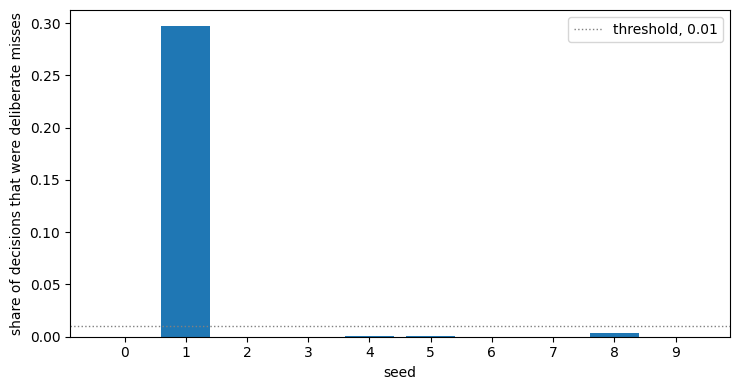

In [12]:
figure, axis = plt.subplots(figsize=(7.5, 4))
axis.bar([str(seed) for seed in SEEDS], [ABSTENTION[seed] for seed in SEEDS])
axis.axhline(HOLDS_FIRE_THRESHOLD, color="grey", linestyle=":", linewidth=1,
             label="threshold, %.2f" % HOLDS_FIRE_THRESHOLD)
axis.set_xlabel("seed")
axis.set_ylabel("share of decisions that were deliberate misses")
axis.legend()
figure.tight_layout()
plt.show()

## How long it took

Recorded because the next decision, whether to go to a larger field, depends on cost. The
runs were trained one after another in this notebook, on one CPU thread.

In [13]:
print("  %-28s %8s" % ("run", "minutes"))
for label in RUN_MINUTES:
    print("  %-28s %8.1f" % (label, RUN_MINUTES[label]))
print("  %-28s %8.1f" % ("total", sum(RUN_MINUTES.values())))

PLAYER_COUNTS = [N]
FIRST_RUN_KEY = (N, SEEDS[0])

  run                           minutes
  N=15 seed 0                       9.8
  N=15 seed 1                      10.4
  N=15 seed 2                       9.3
  N=15 seed 3                       9.5
  N=15 seed 4                      10.0
  N=15 seed 5                       9.5
  N=15 seed 6                       9.6
  N=15 seed 7                       8.4
  N=15 seed 8                       7.5
  N=15 seed 9                       7.1
  total                            91.0


## Reproducibility

Two random streams are reset, not one: the environment's, and torch's global stream, because a
trained policy samples its actions.

In [14]:
def measure_once():
    n = PLAYER_COUNTS[-1]
    torch.manual_seed(7000)
    game = GruelEnv(n=n, reward="terminal", seating="ranked", seed=9000)
    records = play_episodes(game, make_agent_policy(TRAINED[FIRST_RUN_KEY]), 400)
    rates = survival_by_accuracy(records, accuracies_of(n))
    return rates[sorted(rates)[0]]


first = measure_once()
second = measure_once()
print("  first  run:", format(first, ".6f"))
print("  second run:", format(second, ".6f"))
print("  identical:", first == second)

  first  run: 0.085000
  second run: 0.085000
  identical: True
